sigma_i       simulation period       2pi/k*       FFT period
    2.0            6.4389             6.5358        6.4516
    3.0            8.1327             8.4776        8.3333


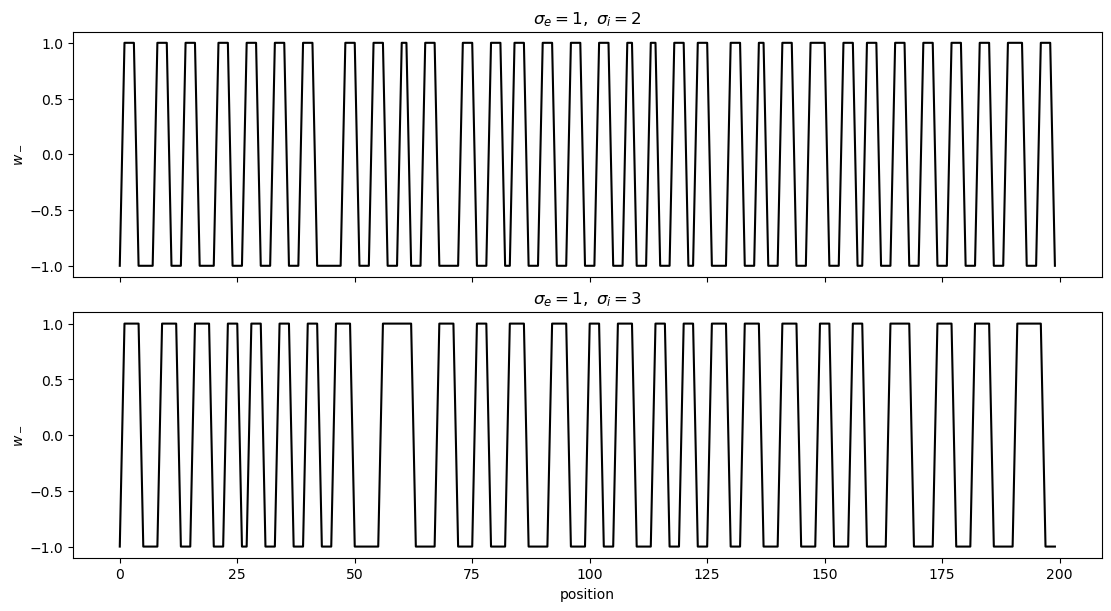

In [22]:
import numpy as np
import matplotlib.pyplot as plt

N = 200
sigma_e = 1.0
sigma_i_values = [2.0, 3.0]

dt = 0.02
t_end = 40.0
n_steps = int(round(t_end / dt))
n_trials = 20

rng = np.random.default_rng(1)

positions = np.arange(N)
distance = np.minimum(positions, N - positions)

fig, axes = plt.subplots(
    2, 1, figsize=(11, 6),
    sharex=True, constrained_layout=True
)

print("sigma_i       simulation period       2pi/k*       FFT period")

for ax, sigma_i in zip(axes, sigma_i_values):

    K = (
        np.exp(-distance**2 / (2 * sigma_e**2))
        - (sigma_e / sigma_i)
        * np.exp(-distance**2 / (2 * sigma_i**2))
    )

    K_fft = np.fft.rfft(K)

    w_minus = rng.normal(0.0, 0.01, size=(n_trials, N))

    for _ in range(n_steps):
        interaction = np.fft.irfft(
            np.fft.rfft(w_minus, axis=1) * K_fft,
            n=N,
            axis=1
        )

        w_minus = np.clip(
            w_minus + dt * interaction, -1.0, 1.0
        )

    
    positive = w_minus > 0
    n_boundaries = np.sum(
        positive != np.roll(positive, 1, axis=1),
        axis=1
    )
    n_pairs = n_boundaries // 2

    periods = np.full(n_trials, np.inf)
    np.divide(N, n_pairs, out=periods, where=n_pairs > 0)
    measured_period = periods.mean()


    k_star = np.sqrt(
        4 * np.log(sigma_i / sigma_e)
        / (sigma_i**2 - sigma_e**2)
    )
    continuum_period = 2 * np.pi / k_star

    modes = np.arange(1, N // 2 + 1)
    k_modes = 2 * np.pi * modes / N

    growth = np.sqrt(2 * np.pi) * sigma_e * (
        np.exp(-sigma_e**2 * k_modes**2 / 2)
        - np.exp(-sigma_i**2 * k_modes**2 / 2)
    )

    m_star = modes[np.argmax(growth)]
    ring_period = N / m_star

    print(
        f"{sigma_i:7.1f}   "
        f"{measured_period:15.4f}   "
        f"{continuum_period:16.4f}   "
        f"{ring_period:11.4f}"
    )

    ax.plot(positions, w_minus[0], color="black")
    ax.set_ylabel(r"$w_-$")
    ax.set_title(
        rf"$\sigma_e={sigma_e:g},\ \sigma_i={sigma_i:g}$"
    )

axes[-1].set_xlabel("position")
plt.show()

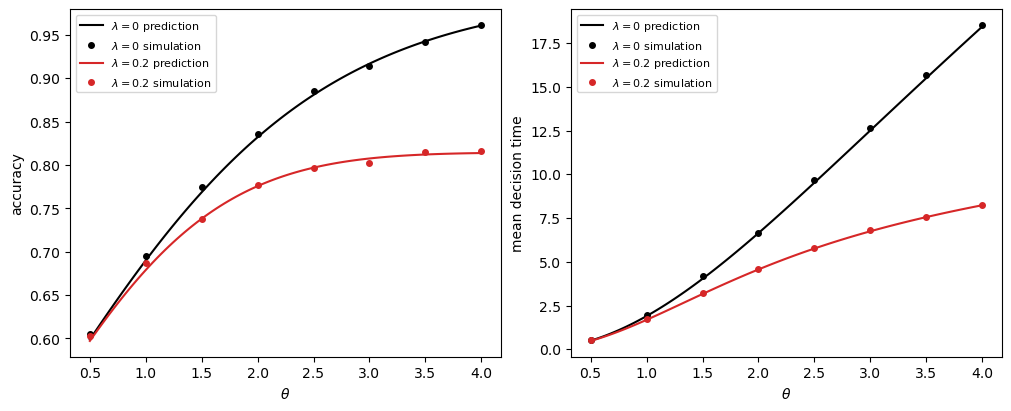

comparison:
threshold: 4.000
mean time: 8.231
(perfect) threshold: 1.843
(perfect) mean time: 5.784


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_bvp
from scipy.special import expit

mu = 0.2
sigma = 0.5
I0 = 5.0

dt = 0.002
n_trials = 10000

thresholds = np.arange(0.5, 4.01, 0.5)
lambda_values = [0.0, 0.2]

rng = np.random.default_rng(1)


def simulate(lam, theta):
    ws = wc = (1 + lam) / 2

    r1 = np.full(n_trials, I0)
    r2 = np.full(n_trials, I0)

    decision_times = np.zeros(n_trials)
    correct = np.zeros(n_trials, dtype=bool)

    active = np.arange(n_trials)
    step = 0

    while active.size > 0:
        a = r1[active]
        b = r2[active]

        r1[active] = (
            a
            + dt * ((ws - 1) * a - wc * b + I0 + mu / 2)
            + sigma * np.sqrt(dt) * rng.normal(size=active.size)
        )

        r2[active] = (
            b
            + dt * ((ws - 1) * b - wc * a + I0 - mu / 2)
            + sigma * np.sqrt(dt) * rng.normal(size=active.size)
        )

        step += 1

        difference = r1[active] - r2[active]
        hit = np.abs(difference) >= theta

        finished = active[hit]
        decision_times[finished] = step * dt
        correct[finished] = difference[hit] > 0

        active = active[~hit]

    return correct.mean(), decision_times.mean()


def prediction(lam, theta):
    if lam == 0:
        accuracy = expit(mu * theta / sigma**2)

        mean_time = (
            theta / mu
            * np.tanh(mu * theta / (2 * sigma**2))
        )

        return accuracy, mean_time

    def g(x):
        return np.exp(
            -(lam * x**2 + 2 * mu * x) / (2 * sigma**2)
        )

    accuracy = (
        quad(g, -theta, 0)[0]
        / quad(g, -theta, theta)[0]
    )

    # y[0] = T, y[1] = T'
    def ode(x, y):
        return np.vstack((
            y[1],
            (-1 - (lam * x + mu) * y[1]) / sigma**2
        ))

    def boundary(ya, yb):
        return np.array([ya[0], yb[0]])

    x = np.linspace(-theta, theta, 101)

    solution = solve_bvp(
        ode,
        boundary,
        x,
        np.zeros((2, x.size)),
        tol=1e-7
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    mean_time = float(solution.sol(0)[0])

    return accuracy, mean_time


results = {}

fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), constrained_layout=True
)

theta_curve = np.linspace(0.5, 4.0, 100)

for lam, color in zip(lambda_values, ["black", "tab:red"]):
    measured = np.array([
        simulate(lam, theta) for theta in thresholds
    ])

    results[lam] = measured

    theoretical = np.array([
        prediction(lam, theta) for theta in theta_curve
    ])

    for j in range(2):
        axes[j].plot(
            theta_curve,
            theoretical[:, j],
            color=color,
            label=rf"$\lambda={lam:g}$ prediction"
        )

        axes[j].plot(
            thresholds,
            measured[:, j],
            "o",
            color=color,
            markersize=4,
            label=rf"$\lambda={lam:g}$ simulation"
        )

axes[0].set_ylabel("accuracy")
axes[1].set_ylabel("mean decision time")

for ax in axes:
    ax.set_xlabel(r"$\theta$")
    ax.legend(fontsize=8)

plt.show()



p_target, t_unstable = prediction(0.2, 4.0)

theta_equal = (
    sigma**2 / mu
    * np.log(p_target / (1 - p_target))
)

_, t_integrator = prediction(0.0, theta_equal)

print(f"comparison:")
print(f"threshold: {4.0:.3f}")
print(f"mean time: {t_unstable:.3f}")
print(f"(perfect) threshold: {theta_equal:.3f}")
print(f"(perfect) mean time: {t_integrator:.3f}")

alpha   fraction         theory     overlap
0.020    0.000              0.000     1.000
0.060    0.000              0.000     1.000
0.100    0.001              0.001     0.999
0.140    0.004              0.004     0.944
0.180    0.009              0.009     0.725
0.220    0.016              0.017     0.386
0.260    0.025              0.025     0.360
0.300    0.032              0.034     0.253
0.340    0.044              0.043     0.262
0.380    0.052              0.052     0.310
0.420    0.062              0.061     0.234
0.460    0.070              0.070     0.341
0.500    0.078              0.079     0.301
0.540    0.084              0.087     0.296
0.580    0.093              0.095     0.322
0.620    0.102              0.102     0.302
Recall breaks down around α = 0.14.


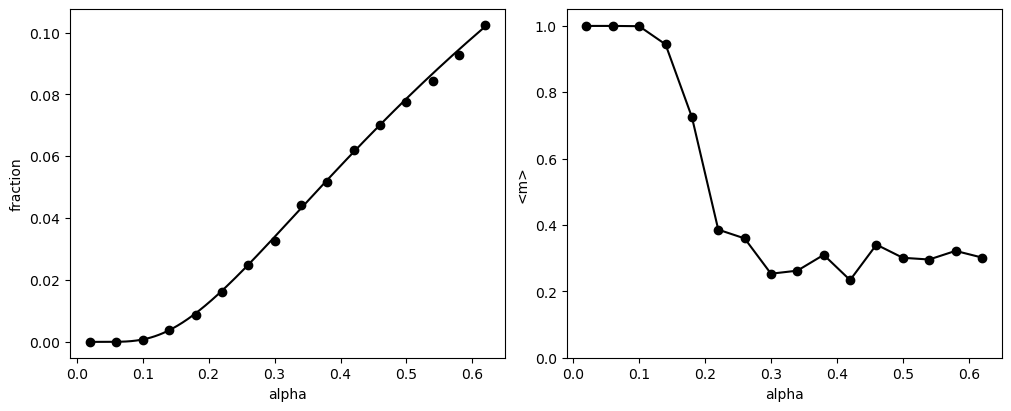

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr

N = 500
alphas = np.arange(0.02, 0.621, 0.04)
n_cues = 10

rng = np.random.default_rng(1)

unstable_fractions = []
mean_overlaps = []


def recall(J, initial_state):
    s = initial_state.copy()
    h = J @ s

    while True:
        changed = False

        for i in rng.permutation(N):
            new_state = 1 if h[i] >= 0 else -1

            if new_state != s[i]:
                delta = new_state - s[i]
                s[i] = new_state

                h += delta * J[:, i]
                changed = True

        if not changed:
            return s


print("alpha   fraction         theory     overlap")

for alpha in alphas:
    P = int(round(alpha * N))

    X = rng.choice([-1, 1], size=(N, P)).astype(np.int32)
    J = X @ X.T
    np.fill_diagonal(J, 0)

    fields = J @ X

    unstable_fraction = np.mean(X * fields < 0)
    unstable_fractions.append(unstable_fraction)

    overlaps = []

    for pattern_index in rng.choice(P, size=n_cues, replace=False):
        target = X[:, pattern_index]
        cue = target.copy()

        flipped = rng.choice(N, size=N // 10, replace=False)
        cue[flipped] *= -1

        final_state = recall(J, cue)

        overlap = np.dot(target, final_state) / N
        overlaps.append(overlap)

    mean_overlap = np.mean(overlaps)
    mean_overlaps.append(mean_overlap)

    theory = ndtr(-1 / np.sqrt(alpha))

    print(
        f"{alpha:.3f}    "
        f"{unstable_fraction:.3f}              "
        f"{theory:.3f}     "
        f"{mean_overlap:.3f}"
    )

print("Recall breaks down around α = 0.14.")


fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), constrained_layout=True
)

alpha_curve = np.linspace(0.02, 0.62, 300)

axes[0].plot(
    alpha_curve,
    ndtr(-1 / np.sqrt(alpha_curve)),
    color="black"
)
axes[0].plot(
    alphas, unstable_fractions,
    "o",
    color="black"
)
axes[0].set_xlabel("alpha")
axes[0].set_ylabel("fraction")


axes[1].plot(alphas, mean_overlaps, "o-", color="black")
axes[1].set_xlabel("alpha")
axes[1].set_ylabel("<m>")
axes[1].set_ylim(0, 1.05)

plt.show()

